In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Sun Aug 23 11:57:29 2026

@author: jeferson
"""

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split


In [2]:
# =============================================================================
# DATA LOADING & INITIAL EXPLORATION
# =============================================================================

# Import dataset
data = pd.read_csv('/home/jeferson/Documentos/Curso Ciência de Dados USP 2026/Projetos/data/open_supply-curve_post_proc.csv')

# Data Exploration
# print("Number of rows and columns: ", data.shape)
# print("\nFirst 10 rows:")
# print(data.head(10))

# print("\nData types:")
# print(data.dtypes)

# print("\nNumber of missing values per column:")
# print(data.isna().sum())

# DataFrame Construction
df = data[
    [
        "mean_depth",  # Average water depth at the site (meters)
        "dist_to_coast_offshore",  # Distance from site to nearest coastline (km)
        "dist_export_km",  # Distance covered by subsea/onshore export cable (km)
        "resource",  # Estimated annual average wind resource at the site (m/s)
        "ncf_2035",  # Net Capacity Factor (%)
        "technology",  # Turbine foundation technology type (fixed-bottom=0, floating=1)
        "all_in_lcoe_2035",  # All-In LCOE
    ]
].copy()

# Convert text column to numeric values inside the same column
df["technology"] = df["technology"].astype("category").cat.codes

print("\nData Summary Statistics:")
print(df.describe())



Data Summary Statistics:
        mean_depth  dist_to_coast_offshore  dist_export_km     resource  \
count  4643.000000             4643.000000     4643.000000  4643.000000   
mean    362.830684               88.375869      150.127619     7.937556   
std     410.217434               72.655188      133.065483     1.227955   
min       6.000000                0.000000        0.045000     3.210638   
25%      41.298327               29.778613       57.536643     7.061746   
50%     141.356920               65.172324      118.250571     7.880521   
75%     723.044770              133.396035      194.899672     8.857931   
max    1299.000000              355.922200      982.942168    11.332843   

          ncf_2035   technology  all_in_lcoe_2035  
count  4643.000000  4643.000000       4643.000000  
mean     40.010933     0.660564        179.277974  
std      10.168184     0.473569        101.824084  
min       5.215148     0.000000         77.143124  
25%      32.215859     0.000000       

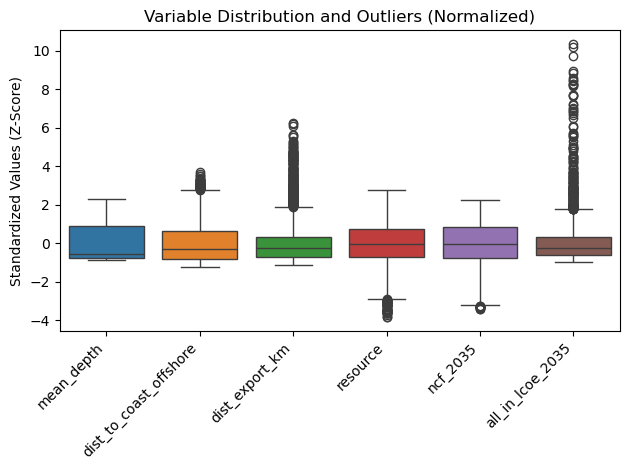

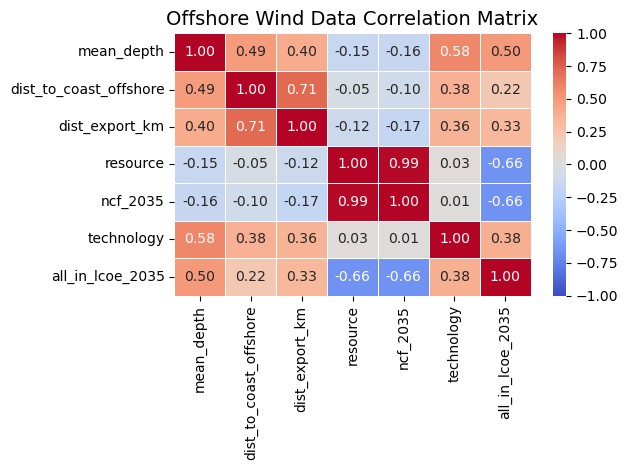

In [3]:
# =============================================================================
# DATA VISUALIZATION
# =============================================================================

# Extract numeric columns for scaling
numeric_cols = df.select_dtypes(include=["float64", "int64"]).columns

# Data Standardization (Mean = 0, Standard Deviation = 1)
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[numeric_cols]), columns=numeric_cols)

# Standardized Boxplot
plt.figure()
sns.boxplot(data=df_scaled)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Standardized Values (Z-Score)")
plt.title("Variable Distribution and Outliers (Normalized)")
plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap
correlation_matrix = df.corr()

plt.figure()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Offshore Wind Data Correlation Matrix", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# DATA SPLITTING
# =============================================================================

# Separate Features (X) and Target (y)
nrow, ncol = df.shape
y = df.iloc[:, -1]
X = df.iloc[:, 0 : ncol - 1]

# Training and Testing Sets Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Cross-validation strategy for both models
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
# =============================================================================
# MODEL 1: POLYNOMIAL REGRESSION PIPELINE WITH REGULARIZATION
# =============================================================================

print("\n[INFO] Running GridSearchCV for Regularized Polynomial Regression...")

# Define the Pipeline: The 'model' step will be dynamically swapped by GridSearchCV
poly_pipeline = Pipeline(
    [
        ("poly", PolynomialFeatures(include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()), 
    ]
)

# Hyperparameter search space configuration
degrees = list(range(1, 11, 3))
alphas = [0.1, 1.0, 10.0]

# List of parameter dictionaries targeting specific models to avoid parameter collision
param_grid = [
    # Configuration A: Standard Linear Regression (No regularization)
    {
        "poly__degree": degrees,
        "model": [LinearRegression()]
    },
    # Configuration B: Ridge Regression (L2 Regularization)
    {
        "poly__degree": degrees,
        "model": [Ridge()],
        "model__alpha": alphas
    },
    # Configuration C: Lasso Regression (L1 Regularization)
    {
        "poly__degree": degrees,
        "model": [Lasso(max_iter=100)], # Increased max_iter to help convergence
        "model__alpha": alphas
    },
    # Configuration D: Elastic Net Regression (Combined L1 & L2 Regularization)
    {
        "poly__degree": degrees,
        "model": [ElasticNet(max_iter=100)],
        "model__alpha": alphas,
        "model__l1_ratio": [0.2, 0.5, 0.8]
    }
]

# Configure GridSearchCV with parallel processing enabled (n_jobs=-1)
poly_grid = GridSearchCV(
    estimator=poly_pipeline,
    param_grid=param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
poly_grid.fit(X_train, y_train)

# Extract optimal parameter values found
best_params = poly_grid.best_params_
best_model_obj = best_params["model"]
best_degree = best_params["poly__degree"]
best_poly_cv_rmse = (-poly_grid.best_score_) ** 0.5

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH")
print("-" * 60)
print(f"Best Model Type:            {best_model_obj.__class__.__name__}")
print(f"Best Polynomial Degree:     {best_degree}")
if "model__alpha" in best_params:
    print(f"Best Alpha (Penalty):       {best_params['model__alpha']}")
if "model__l1_ratio" in best_params:
    print(f"Best L1 Ratio (ElasticNet): {best_params['model__l1_ratio']}")
print(f"Best Cross-Validation RMSE: {best_poly_cv_rmse:.4f}")
print("-" * 60)

# Retrieve the automatically refitted best estimator model
best_poly_model = poly_grid.best_estimator_

# Generate predictions on unseen test dataset using the optimal configuration
y_pred_poly = best_poly_model.predict(X_test)

# Calculate final test evaluation metrics
poly_r2 = r2_score(y_test, y_pred_poly)
poly_mae = mean_absolute_error(y_test, y_pred_poly)
poly_mse = mean_squared_error(y_test, y_pred_poly)
poly_rmse = np.sqrt(poly_mse)

print("\n" + "-" * 60)
print("FINAL TEST DATASET METRICS")
print("-" * 60)
print(f"R² (Coefficient of Determination): {poly_r2:.4f}")
print(f"MAE (Mean Absolute Error):         {poly_mae:.4f}")
print(f"RMSE (Root Mean Squared Error):    {poly_rmse:.4f}")
print("-" * 60)

# Actual vs. Predicted Plot
plt.figure()
l_poly = plt.plot(y_pred_poly, y_test, "bo")
plt.setp(l_poly, markersize=8)
plt.setp(l_poly, markerfacecolor="C0")
plt.ylabel("Actual Values (y)", fontsize=12)
plt.xlabel("Predictions", fontsize=12)
min_val_poly = min(min(y_test), min(y_pred_poly))
max_val_poly = max(max(y_test), max(y_pred_poly))
xl_poly = np.linspace(min_val_poly, max_val_poly, 100)
plt.plot(xl_poly, xl_poly, "r--")
plt.title(f"Actual vs. Predicted ({best_model_obj.__class__.__name__} - Degree {best_degree})")
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for K-NN Regressor...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (K-NN)
------------------------------------------------------------
Best Number of Neighbors (k): 10
Best Cross-Validation RMSE:   26.6473
------------------------------------------------------------

------------------------------------------------------------
FINAL K-NN REGRESSOR TEST DATASET METRICS
------------------------------------------------------------
R² (Coefficient of Determination): 0.9437
MAE (Mean Absolute Error):         12.7841
RMSE (Root Mean Squared Error):    23.4015
------------------------------------------------------------


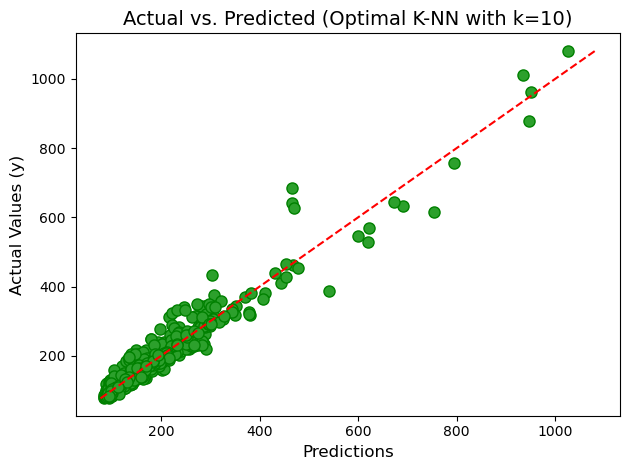

In [6]:
# =============================================================================
# MODEL 2: K-NEAREST NEIGHBORS (K-NN) PIPELINE & GRIDSEARCH
# =============================================================================

print("\n[INFO] Running GridSearchCV for K-NN Regressor...")

# K-NN calculates distances, so feature scaling (StandardScaler) is mandatory
knn_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", KNeighborsRegressor())]
)

# Hyperparameter grid configuration for K-NN optimization
knn_param_grid = {
    'model__n_neighbors': [3, 5, 10, 20],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
knn_grid.fit(X_train, y_train)

# Extract K-NN Errors
knn_cv = knn_grid.cv_results_
knn_train_rmse = np.sqrt(-knn_cv["mean_train_score"])
knn_val_rmse = np.sqrt(-knn_cv["mean_test_score"])

# Extract optimal parameter values found for K-NN
best_k = knn_grid.best_params_["model__n_neighbors"]
best_knn_cv_rmse = (-knn_grid.best_score_) ** 0.5

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (K-NN)")
print("-" * 60)
print(f"Best Number of Neighbors (k): {best_k}")
print(f"Best Cross-Validation RMSE:   {best_knn_cv_rmse:.4f}")
print("-" * 60)

# Retrieve the automatically refitted best estimator model for K-NN
best_knn_model = knn_grid.best_estimator_

# Generate predictions on unseen test dataset using the optimal configuration
y_pred_knn = best_knn_model.predict(X_test)

# Calculate final test evaluation metrics
knn_r2 = r2_score(y_test, y_pred_knn)
knn_mae = mean_absolute_error(y_test, y_pred_knn)
knn_mse = mean_squared_error(y_test, y_pred_knn)
knn_rmse = np.sqrt(knn_mse)

print("\n" + "-" * 60)
print("FINAL K-NN REGRESSOR TEST DATASET METRICS")
print("-" * 60)
print(f"R² (Coefficient of Determination): {knn_r2:.4f}")
print(f"MAE (Mean Absolute Error):         {knn_mae:.4f}")
print(f"RMSE (Root Mean Squared Error):    {knn_rmse:.4f}")
print("-" * 60)

# Actual vs. Predicted Plot (K-NN)
plt.figure()
l_knn = plt.plot(y_pred_knn, y_test, "go")  # Green points to differentiate from Polynomial
plt.setp(l_knn, markersize=8)
plt.setp(l_knn, markerfacecolor="C2")
plt.ylabel("Actual Values (y)", fontsize=12)
plt.xlabel("Predictions", fontsize=12)
min_val_knn = min(min(y_test), min(y_pred_knn))
max_val_knn = max(max(y_test), max(y_pred_knn))
xl_knn = np.linspace(min_val_knn, max_val_knn, 100)
plt.plot(xl_knn, xl_knn, "r--")
plt.title(f"Actual vs. Predicted (Optimal K-NN with k={best_k})", fontsize=14)
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for Decision Tree Regressor...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (DECISION TREE)
------------------------------------------------------------
Best Max Depth:             10
Best Cross-Validation RMSE: 30.8169
------------------------------------------------------------

------------------------------------------------------------
FINAL DECISION TREE REGRESSOR TEST DATASET METRICS
------------------------------------------------------------
R² (Coefficient of Determination): 0.9224
MAE (Mean Absolute Error):         15.0723
RMSE (Root Mean Squared Error):    27.4819
------------------------------------------------------------


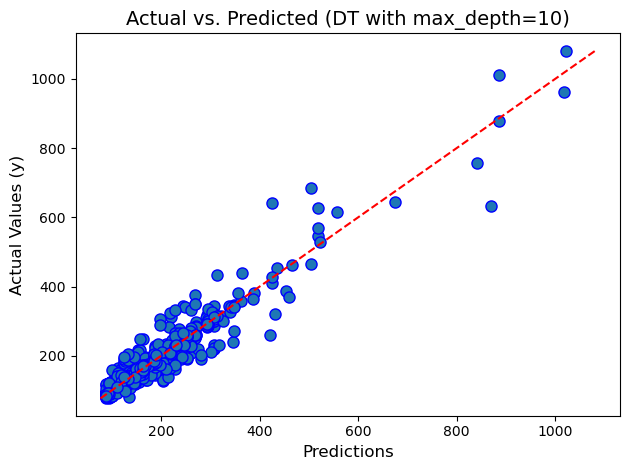

In [7]:
# =============================================================================
# MODEL 3: DECISION TREE REGRESSOR PIPELINE & GRIDSEARCH
# =============================================================================

print("\n[INFO] Running GridSearchCV for Decision Tree Regressor...")

# Decision Trees don't require scaling, but keeping the pipeline structure for consistency
dt_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", DecisionTreeRegressor(random_state=42))]
)

# Hyperparameter grid configuration for Decision Tree optimization
dt_param_grid = {
    'model__max_depth': [None, 5, 10, 15, 20],
    'model__max_features': [None, 'sqrt', 'log2']
}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
dt_grid.fit(X_train, y_train)

# Extract Decision Tree Errors
dt_cv = dt_grid.cv_results_
dt_train_rmse = np.sqrt(-dt_cv["mean_train_score"])
dt_val_rmse = np.sqrt(-dt_cv["mean_test_score"])

# Extract optimal parameter values found for Decision Tree
best_depth = dt_grid.best_params_["model__max_depth"]
best_dt_cv_rmse = (-dt_grid.best_score_) ** 0.5

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (DECISION TREE)")
print("-" * 60)
print(f"Best Max Depth:             {best_depth}")
print(f"Best Cross-Validation RMSE: {best_dt_cv_rmse:.4f}")
print("-" * 60)

# Retrieve the automatically refitted best estimator model for Decision Tree
best_dt_model = dt_grid.best_estimator_

# Generate predictions on unseen test dataset using the optimal configuration
y_pred_dt = best_dt_model.predict(X_test)

# Calculate final test evaluation metrics
dt_r2 = r2_score(y_test, y_pred_dt)
dt_mae = mean_absolute_error(y_test, y_pred_dt)
dt_mse = mean_squared_error(y_test, y_pred_dt)
dt_rmse = np.sqrt(dt_mse)

print("\n" + "-" * 60)
print("FINAL DECISION TREE REGRESSOR TEST DATASET METRICS")
print("-" * 60)
print(f"R² (Coefficient of Determination): {dt_r2:.4f}")
print(f"MAE (Mean Absolute Error):         {dt_mae:.4f}")
print(f"RMSE (Root Mean Squared Error):    {dt_rmse:.4f}")
print("-" * 60)

# Actual vs. Predicted Plot (Decision Tree)
plt.figure()
l_dt = plt.plot(y_pred_dt, y_test, "bo")  # Blue points to differentiate from K-NN and Polynomial
plt.setp(l_dt, markersize=8)
plt.setp(l_dt, markerfacecolor="C0")
plt.ylabel("Actual Values (y)", fontsize=12)
plt.xlabel("Predictions", fontsize=12)
min_val_dt = min(min(y_test), min(y_pred_dt))
max_val_dt = max(max(y_test), max(y_pred_dt))
xl_dt = np.linspace(min_val_dt, max_val_dt, 100)
plt.plot(xl_dt, xl_dt, "r--")
plt.title(f"Actual vs. Predicted (DT with max_depth={best_depth})", fontsize=14)
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for Random Forest Regressor...
------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (RANDOM FOREST)
------------------------------------------------------------
Best Max Depth:             None
Best Estimators (Trees):    300
Best Cross-Validation RMSE: 24.6075
------------------------------------------------------------

------------------------------------------------------------
FINAL RANDOM FOREST REGRESSOR TEST DATASET METRICS
------------------------------------------------------------
R² (Coefficient of Determination): 0.9550
MAE (Mean Absolute Error):         11.4000
RMSE (Root Mean Squared Error):    20.9172
------------------------------------------------------------


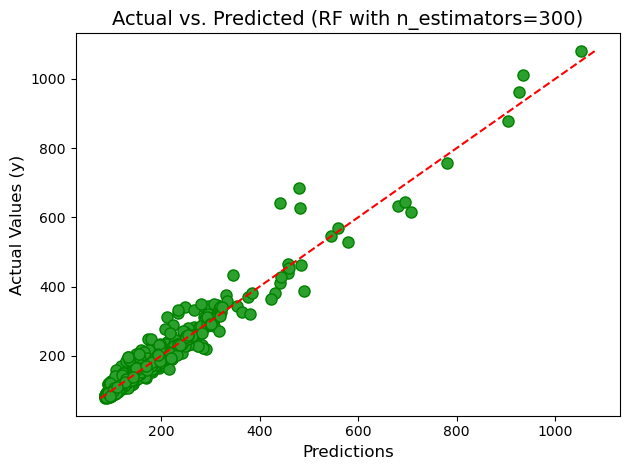


[INFO] Generating Feature Importance for Random Forest Regressor...


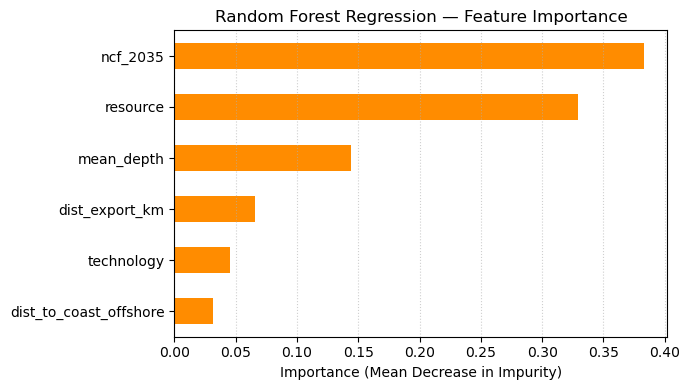

In [8]:
# =============================================================================
# MODEL 4: RANDOM FOREST REGRESSOR PIPELINE & GRIDSEARCH
# =============================================================================

print("\n[INFO] Running GridSearchCV for Random Forest Regressor...")

# Pipeline structure for Random Forest
rf_pipeline = Pipeline(
    [("scaler", StandardScaler()), 
     ("model", RandomForestRegressor(random_state=42))]
)

# Hyperparameter grid configuration for Random Forest optimization
rf_param_grid = {
    'model__n_estimators': [50, 100, 200, 300],
    'model__max_depth': [None, 10, 20],
    'model__max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
rf_grid.fit(X_train, y_train)

# Extract Random Forest Errors
rf_cv = rf_grid.cv_results_
rf_train_rmse = np.sqrt(-rf_cv["mean_train_score"])
rf_val_rmse = np.sqrt(-rf_cv["mean_test_score"])

# Extract optimal parameter values found for Random Forest
best_depth_rf = rf_grid.best_params_["model__max_depth"]
best_estimators_rf = rf_grid.best_params_["model__n_estimators"]
best_rf_cv_rmse = (-rf_grid.best_score_) ** 0.5

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (RANDOM FOREST)")
print("-" * 60)
print(f"Best Max Depth:             {best_depth_rf}")
print(f"Best Estimators (Trees):    {best_estimators_rf}")
print(f"Best Cross-Validation RMSE: {best_rf_cv_rmse:.4f}")
print("-" * 60)

# Retrieve the automatically refitted best estimator model for Random Forest
best_rf_model = rf_grid.best_estimator_

# Generate predictions on unseen test dataset using the optimal configuration
y_pred_rf = best_rf_model.predict(X_test)

# Calculate final test evaluation metrics
rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)

print("\n" + "-" * 60)
print("FINAL RANDOM FOREST REGRESSOR TEST DATASET METRICS")
print("-" * 60)
print(f"R² (Coefficient of Determination): {rf_r2:.4f}")
print(f"MAE (Mean Absolute Error):         {rf_mae:.4f}")
print(f"RMSE (Root Mean Squared Error):    {rf_rmse:.4f}")
print("-" * 60)

# Actual vs. Predicted Plot (Random Forest)
plt.figure()
l_rf = plt.plot(y_pred_rf, y_test, "go")  # Green points to differentiate from others
plt.setp(l_rf, markersize=8)
plt.setp(l_rf, markerfacecolor="C2")
plt.ylabel("Actual Values (y)", fontsize=12)
plt.xlabel("Predictions", fontsize=12)
min_val_rf = min(min(y_test), min(y_pred_rf))
max_val_rf = max(max(y_test), max(y_pred_rf))
xl_rf = np.linspace(min_val_rf, max_val_rf, 100)
plt.plot(xl_rf, xl_rf, "r--")
plt.title(f"Actual vs. Predicted (RF with n_estimators={best_estimators_rf})", fontsize=14)
plt.tight_layout()
plt.show()

# Feature Importance for Regression
print("\n[INFO] Generating Feature Importance for Random Forest Regressor...")
#
# Extract the fitted model from the pipeline and the column names
rf_features = X_train.columns if hasattr(X_train, 'columns') else [f"Feature {i}" for i in range(X_train.shape[1])]
best_rf_clf = best_rf_model.named_steps["model"]

# Create a Series containing feature importances
importances_clf = pd.Series(best_rf_clf.feature_importances_, index=rf_features)
importances_clf = importances_clf.sort_values(ascending=False)

# 3. Plot horizontal bar chart
plt.figure(figsize=(7, 4))
importances_clf.plot(kind='barh', color='darkorange')
plt.gca().invert_yaxis()  
plt.xlabel('Importance (Mean Decrease in Impurity)')
plt.title('Random Forest Regression — Feature Importance')
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


[INFO] Running GridSearchCV for Multilayer Perceptron Regressor...


/home/jeferson/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jeferson/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jeferson/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jeferson/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/jeferson/anaconda3

------------------------------------------------------------
OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (MLP REGRESSOR)
------------------------------------------------------------
Best Hidden Layer Sizes:         (50, 50)
Best Activation Function:       relu
Best Alpha (L2 Regularization): 0.01
Best Initial Learning Rate:     0.001
Best Cross-Validation RMSE:     25.9832
------------------------------------------------------------

------------------------------------------------------------
FINAL MLP REGRESSOR TEST DATASET METRICS
------------------------------------------------------------
R² (Coefficient of Determination): 0.9462
MAE (Mean Absolute Error):         14.2081
RMSE (Root Mean Squared Error):    22.8770
------------------------------------------------------------


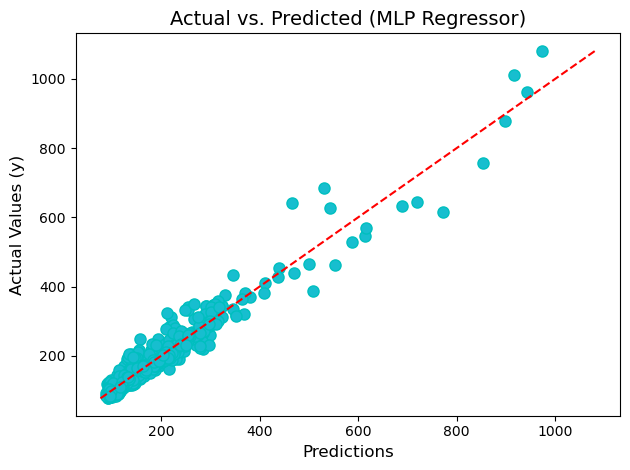


[INFO] Generating epoch-by-epoch Training vs. Validation curves...


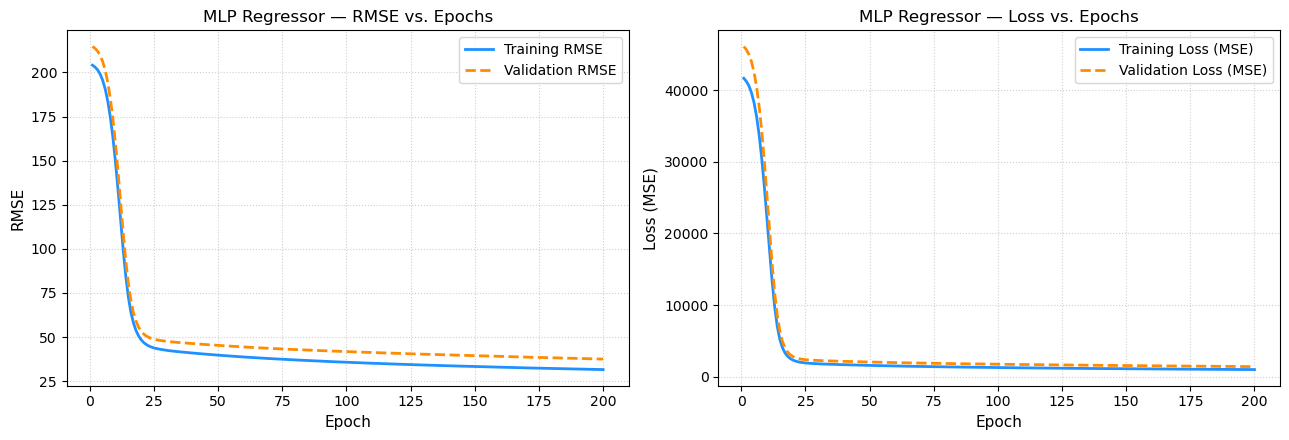

In [14]:
# =============================================================================
# MODEL 5: MULTILAYER PERCEPTRON (MLP) REGRESSOR 
# =============================================================================
print("\n[INFO] Running GridSearchCV for Multilayer Perceptron Regressor...")

# Pipeline structure for MLP Regressor
mlp_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("model", MLPRegressor(solver="adam", max_iter=1000, random_state=42))
    ]
)

# Hyperparameter grid configuration for MLP optimization
mlp_param_grid = {
    'model__hidden_layer_sizes': [(100,), (50, 50)],
    'model__activation': ['tanh', 'relu'],
    'model__alpha': [1e-3, 1e-2],
    'model__learning_rate_init': [1e-3, 1e-2]
}

mlp_grid = GridSearchCV(
    estimator=mlp_pipeline,
    param_grid=mlp_param_grid,
    cv=kf,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

# Run hyperparameter search using training data
mlp_grid.fit(X_train, y_train)

# Extract optimal parameter values found for MLP
best_params_mlp = mlp_grid.best_params_
best_hidden_layers = best_params_mlp["model__hidden_layer_sizes"]
best_activation = best_params_mlp["model__activation"]
best_alpha = best_params_mlp["model__alpha"]
best_lr_init = best_params_mlp["model__learning_rate_init"]
best_mlp_cv_rmse = (-mlp_grid.best_score_) ** 0.5

print("-" * 60)
print("OPTIMAL HYPERPARAMETERS FOUND BY GRIDSEARCH (MLP REGRESSOR)")
print("-" * 60)
print(f"Best Hidden Layer Sizes:         {best_hidden_layers}")
print(f"Best Activation Function:       {best_activation}")
print(f"Best Alpha (L2 Regularization): {best_alpha}")
print(f"Best Initial Learning Rate:     {best_lr_init}")
print(f"Best Cross-Validation RMSE:     {best_mlp_cv_rmse:.4f}")
print("-" * 60)

# Retrieve the automatically refitted best estimator model for MLP
best_mlp_model = mlp_grid.best_estimator_

# Generate predictions on unseen test dataset using the optimal configuration
y_pred_mlp = best_mlp_model.predict(X_test)

# Calculate final test evaluation metrics
mlp_r2 = r2_score(y_test, y_pred_mlp)
mlp_mae = mean_absolute_error(y_test, y_pred_mlp)
mlp_mse = mean_squared_error(y_test, y_pred_mlp)
mlp_rmse = np.sqrt(mlp_mse)

print("\n" + "-" * 60)
print("FINAL MLP REGRESSOR TEST DATASET METRICS")
print("-" * 60)
print(f"R² (Coefficient of Determination): {mlp_r2:.4f}")
print(f"MAE (Mean Absolute Error):         {mlp_mae:.4f}")
print(f"RMSE (Root Mean Squared Error):    {mlp_rmse:.4f}")
print("-" * 60)

# Actual vs. Predicted Plot (MLP Regressor)
plt.figure()
l_mlp = plt.plot(y_pred_mlp, y_test, "co")  
plt.setp(l_mlp, markersize=8)
plt.setp(l_mlp, markerfacecolor="C9")
plt.ylabel("Actual Values (y)", fontsize=12)
plt.xlabel("Predictions", fontsize=12)
min_val_mlp = min(min(y_test), min(y_pred_mlp))
max_val_mlp = max(max(y_test), max(y_pred_mlp))
xl_mlp = np.linspace(min_val_mlp, max_val_mlp, 100)
plt.plot(xl_mlp, xl_mlp, "r--")
plt.title("Actual vs. Predicted (MLP Regressor)", fontsize=14)
plt.tight_layout()
plt.show()

# MLP Convergence Analysis
print("\n[INFO] Generating epoch-by-epoch Training vs. Validation curves...")

# Split X_train into Train and Validation sets for monitoring
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

scaler_epoch = StandardScaler()
X_tr_s = scaler_epoch.fit_transform(X_tr)
X_val_s = scaler_epoch.transform(X_val)

# Instantiate MLPRegressor with optimal hyperparameters
best_mlp_epoch = MLPRegressor(
    hidden_layer_sizes=best_hidden_layers,
    activation=best_activation,
    alpha=best_alpha,
    learning_rate_init=best_lr_init,
    solver="adam",
    random_state=42
)

epochs_count = 200
train_loss_history, val_loss_history = [], []
train_rmse_history, val_rmse_history = [], []

# Optimized Epoch loop using partial_fit
for _ in range(epochs_count):
    best_mlp_epoch.partial_fit(X_tr_s, y_tr)

    # Single pass for predictions
    tr_pred = best_mlp_epoch.predict(X_tr_s)
    val_pred = best_mlp_epoch.predict(X_val_s)

    # Compute MSE (Loss) and RMSE
    tr_mse = mean_squared_error(y_tr, tr_pred)
    val_mse = mean_squared_error(y_val, val_pred)

    train_loss_history.append(tr_mse)
    val_loss_history.append(val_mse)

    train_rmse_history.append(np.sqrt(tr_mse))
    val_rmse_history.append(np.sqrt(val_mse))

epochs_range = range(1, epochs_count + 1)

# Convergence Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
#
# RMSE Plot
ax1.plot(epochs_range, train_rmse_history, label="Training RMSE", color="dodgerblue", lw=2)
ax1.plot(epochs_range, val_rmse_history, label="Validation RMSE", color="darkorange", lw=2, linestyle="--")
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("RMSE", fontsize=11)
ax1.set_title("MLP Regressor — RMSE vs. Epochs", fontsize=12)
ax1.legend(loc="upper right", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6)
#
# Loss (MSE) Plot
ax2.plot(epochs_range, train_loss_history, label="Training Loss (MSE)", color="dodgerblue", lw=2)
ax2.plot(epochs_range, val_loss_history, label="Validation Loss (MSE)", color="darkorange", lw=2, linestyle="--")
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Loss (MSE)", fontsize=11)
ax2.set_title("MLP Regressor — Loss vs. Epochs", fontsize=12)
ax2.legend(loc="upper right", fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.6)
#
plt.tight_layout()
plt.show()


In [15]:
# =============================================================================
# FINAL COMPARISON ON THE TEST SET (UNSEEN DATA)
# =============================================================================

print("\n" + "=" * 118)
print("COMPARAÇÃO DE DESEMPENHO FINAL (DADOS DE TESTE)")
print("=" * 118)
print(f"{'Métrica':<10} | {'Regressão Polinomial':<22} | {'K-NN Regressor':<15} | {'Decision Tree':<15} | {'Random Forest':<15} | {'MLP Regressor':<15}")
print("-" * 118)
print(f"{'R²':<10} | {poly_r2:<22.4f} | {knn_r2:<15.4f} | {dt_r2:<15.4f} | {rf_r2:<15.4f} | {mlp_r2:<15.4f}")
print(f"{'MAE':<10} | {poly_mae:<22.4f} | {knn_mae:<15.4f} | {dt_mae:<15.4f} | {rf_mae:<15.4f} | {mlp_mae:<15.4f}")
print(f"{'RMSE':<10} | {poly_rmse:<22.4f} | {knn_rmse:<15.4f} | {dt_rmse:<15.4f} | {rf_rmse:<15.4f} | {mlp_rmse:<15.4f}")
print("=" * 118)


COMPARAÇÃO DE DESEMPENHO FINAL (DADOS DE TESTE)
Métrica    | Regressão Polinomial   | K-NN Regressor  | Decision Tree   | Random Forest   | MLP Regressor  
----------------------------------------------------------------------------------------------------------------------
R²         | 0.9446                 | 0.9437          | 0.9224          | 0.9550          | 0.9462         
MAE        | 13.8608                | 12.7841         | 15.0723         | 11.4000         | 14.2081        
RMSE       | 23.2110                | 23.4015         | 27.4819         | 20.9172         | 22.8770        
